# Phase 3.2 — LSTM: Sequence-to-One Time-Series Forecasting

**Research question:** Does an LSTM that processes consecutive financial feature vectors improve directional probability forecasting beyond tabular classical ML and MLP?

Run **first**: `python -m quant_trading.phase3_lstm` (after Phase 1, all Phase 2 scripts, and Phase 3.1). Model selection is based on training-era chronological CV: `sequence_length ∈ {10,20,40}` × `hidden_size ∈ {8,16}` × 4 folds × 3 seeds = **72 fits**. One fitted scaler per training fold; sequences terminate at the signal close.

The full feature-only session history is used for continuity around purged label boundaries. Validation and final test labels are **never** used to fit scalers or tune LSTM. All full-model training is in `src/quant_trading/lstm_model.py`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

current_dir = Path.cwd().resolve()
for ROOT in (current_dir, *current_dir.parents):
    if (ROOT / "src" / "quant_trading" / "pipeline.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter inside the extracted project.")
REPORT = ROOT / 'reports' / 'phase3_2'
assert (REPORT / 'config.json').is_file(), 'Run python -m quant_trading.phase3_lstm first.'
config = json.loads((REPORT / 'config.json').read_text(encoding='utf-8'))
print('Selected LSTM:', config['selected'])
print('Common train signals:', config['common_training_observations'])
print('Final test used:', config['test_used'])

Selected LSTM: {'sequence_length': 40, 'hidden_size': 8}
Common train signals: 3419
Final test used: False


## 1 — Selection across sequence lengths and hidden sizes

All candidates use the same eligible training signals and the same fold validation dates. The `sequence_length` refers to feature input history, *not* label horizon.

CV fits: 72


,sequence_length,hidden_size,cv_log_loss,cv_log_loss_std,cv_brier_score,cv_roc_auc
0,40,8,0.711061,0.024737,0.258322,0.475513
1,10,8,0.712056,0.017841,0.258965,0.470917
2,20,8,0.712748,0.024921,0.259106,0.470718
3,10,16,0.735745,0.018426,0.268539,0.495271
4,40,16,0.735983,0.021368,0.268887,0.494306
5,20,16,0.739792,0.024254,0.270668,0.489631


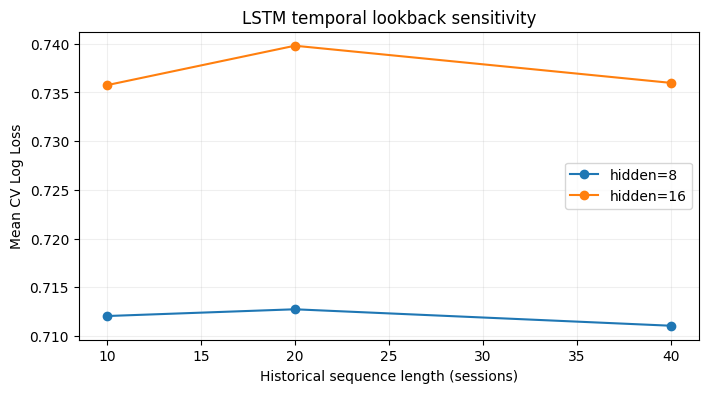

In [2]:
folds = pd.read_csv(REPORT / 'cv_folds_seeds.csv')
summary = pd.read_csv(REPORT / 'cv_summary.csv').sort_values('cv_log_loss')
display(summary)
print('CV fits:', len(folds))
fig, ax = plt.subplots(figsize=(8,4))
for hidden, group in summary.groupby('hidden_size'):
    group = group.sort_values('sequence_length')
    ax.plot(group.sequence_length, group.cv_log_loss,marker='o', label=f'hidden={hidden}')
ax.set(xlabel='Historical sequence length (sessions)', ylabel='Mean CV Log Loss',
       title='LSTM temporal lookback sensitivity')
ax.grid(alpha=.2); ax.legend()
plt.show()
assert folds.groupby('fold')['validation_start'].nunique().eq(1).all()

## 2 — Random initialization and optimization stability

Three predetermined seeds are evaluated. These are NOT statistically independent market samples.

seed,11,42,73
fold,,,
1,0.735593,0.727847,0.736976
2,0.701977,0.759543,0.721052
3,0.684282,0.686249,0.682030
4,0.697845,0.695578,0.703765


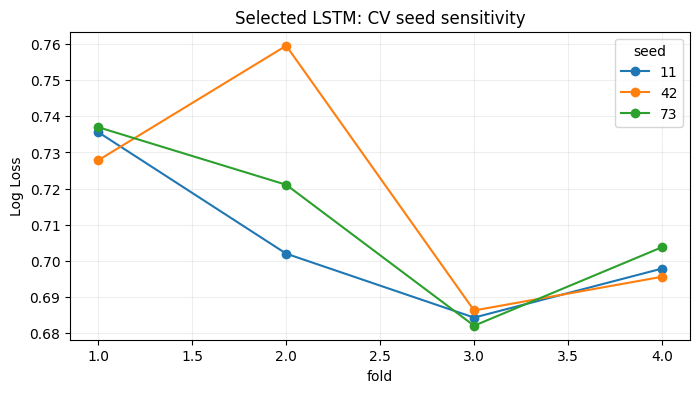

,split,log_loss,brier_score,roc_auc
0,train,0.656532,0.232381,0.640398
1,validation,0.725708,0.262628,0.485388


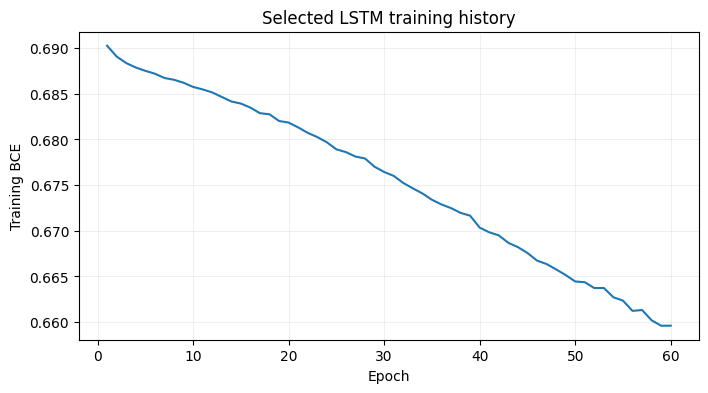

In [3]:
best = config['selected']
chosen = folds.loc[(folds.sequence_length == best['sequence_length']) &
                   (folds.hidden_size == best['hidden_size'])]
seed_pivot = chosen.pivot(index='fold', columns='seed', values='log_loss')
display(seed_pivot)
seed_pivot.plot(marker='o', figsize=(8,4),title='Selected LSTM: CV seed sensitivity')
plt.ylabel('Log Loss'); plt.grid(alpha=.2)
plt.show()
learning = pd.read_csv(REPORT / 'training_losses.csv')
split_metrics = pd.read_csv(REPORT / 'train_vs_validation_metrics.csv')
display(split_metrics[['split','log_loss','brier_score','roc_auc']])
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(learning.epoch, learning.train_loss)
ax.set(xlabel='Epoch', ylabel='Training BCE', title='Selected LSTM training history')
ax.grid(alpha=.2)
plt.show()

## 3 — All five model families on aligned signal dates

The baseline, Logistic Regression, XGBoost, MLP and LSTM are scored on **identical** 2019–2021 validation observations. Prior model predictions are reused, not re-trained with validation labels.

,model,log_loss,brier_score,roc_auc
0,Constant Probability,0.679269,0.243076,0.500000
1,XGBoost,0.686009,0.246405,0.495446
2,Logistic Regression,0.687180,0.246934,0.486930
3,MLP,0.714403,0.256210,0.496893
4,LSTM,0.725708,0.262628,0.485388


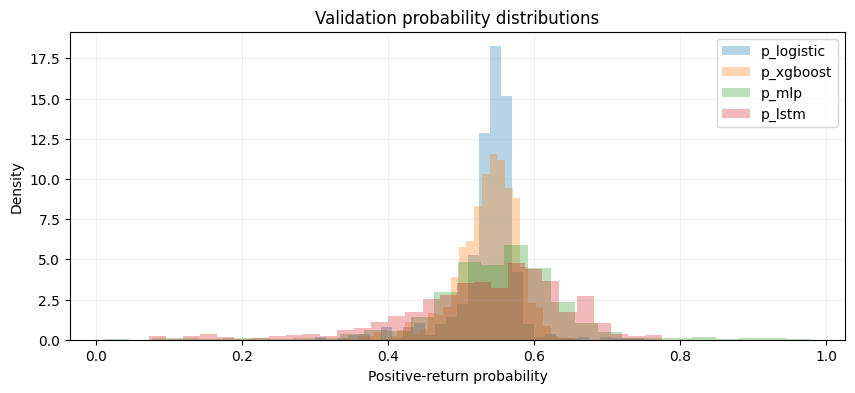

In [4]:
pred = pd.read_csv(REPORT / 'validation_predictions.csv',
                   parse_dates=['signal_date']).set_index('signal_date')
metrics = pd.read_csv(REPORT / 'validation_metrics.csv')
assert pred.index.is_unique and pred.index.is_monotonic_increasing
assert pred.index.max() < pd.Timestamp('2022-01-01')
cols = ['p_baseline','p_logistic','p_xgboost','p_mlp','p_lstm']
assert pred[cols].notna().all().all()
display(metrics[['model','log_loss','brier_score','roc_auc']].sort_values('log_loss'))
fig, ax = plt.subplots(figsize=(10,4))
for col in ['p_logistic','p_xgboost','p_mlp','p_lstm']:
    ax.hist(pred[col], bins=30, alpha=.32, density=True, label=col)
ax.set(xlabel='Positive-return probability', ylabel='Density',title='Validation probability distributions')
ax.grid(alpha=.2); ax.legend()
plt.show()

## 4 — Probability calibration and temporal performance

This is a development-stage diagnostic; **do not** use these plots to tune further hyperparameters and call the same period independent validation.

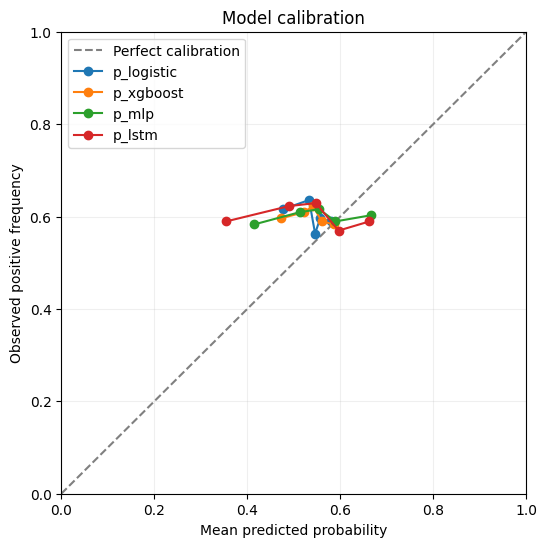

model,p_baseline,p_logistic,p_lstm,p_mlp,p_xgboost
year,,,,,
2019,0.679410,0.679086,0.689975,0.702528,0.677786
2020,0.680539,0.705709,0.778240,0.752713,0.700797
2021,0.677840,0.676587,0.708565,0.687603,0.679333


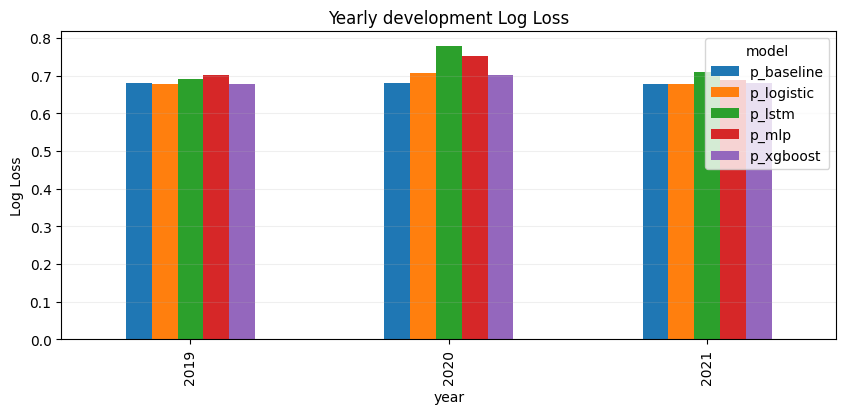

In [5]:
fig, ax = plt.subplots(figsize=(6,6))
ax.plot([0,1],[0,1],ls='--',color='gray',label='Perfect calibration')
for col in ['p_logistic','p_xgboost','p_mlp','p_lstm']:
    observed, predicted = calibration_curve(pred.actual_label, pred[col], n_bins=5, strategy='quantile')
    ax.plot(predicted, observed, marker='o', label=col)
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',
       ylabel='Observed positive frequency',title='Model calibration')
ax.legend(); ax.grid(alpha=.2)
plt.show()
from sklearn.metrics import log_loss
rows = []
for yr, sub in pred.groupby(pred.index.year):
    for col in cols:
        rows.append({'year':yr,'model':col,'log_loss':log_loss(sub.actual_label,sub[col],labels=[0,1])})
by_year = pd.DataFrame(rows)
display(by_year.pivot(index='year',columns='model',values='log_loss'))
by_year.pivot(index='year',columns='model',values='log_loss').plot.bar(figsize=(10,4),title='Yearly development Log Loss')
plt.ylabel('Log Loss'); plt.grid(axis='y',alpha=.2)
plt.show()

## Does a sequence of past sessions improve the forecast?

- **Model comparison.** The selected LSTM scores 0.72571 on validation Log Loss. Both nonlinear tabular models do better (MLP 0.71440 and XGBoost 0.68601). The constant prior scores 0.67927.
- **Lookback, seeds and folds.** With eight hidden units, mean training-era CV Log Loss is 0.71106 for 40 sessions, 0.71206 for 10 and 0.71275 for 20. With 16 units all three scores exceed 0.735. For the winning configuration the within-fold spread over seeds is 0.0091, 0.0576, 0.0042 and 0.0082. Forty sessions is the CV winner here. The small margin and variable seed results provide little support for a stable lookback advantage. Only the selected configuration received an outer validation score.
- **Calibration.** The lowest and highest probability quintiles predict 35.45% and 66.27%, yet each group has 58.94% up days (151 observations per group). The extreme probabilities show poor calibration and little useful separation over these dates.
- **Generalization.** Training Log Loss is 0.65653 and validation Log Loss is 0.72571. AUC drops from 0.640 to 0.485. The pattern is consistent with weak generalization despite improving the training objective.